# Even More Basic Experiment

This notebook creates a heatmap showing isometry pursuit success rates where:
- **X-axis**: Embedding dimension (D)
- **Y-axis**: Number of corrupting matrices of dimension (D-1)

For each configuration, we test whether isometry pursuit correctly selects the full D×D identity matrix.


In [85]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tqdm import tqdm
from isometry_pursuit.algorithm import isometry_pursuit
from isometry_pursuit.exec.generate_orthogonal_data import generate_orthogonal_data

np.random.seed(1234)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [86]:
# Define parameter grid
D_values = [2, 4, 6, 8, 10, 12, 14, 16]  # Embedding dimensions (x-axis)
num_corrupting_values = [1, 2, 4, 8, 16]  # Number of corrupting matrices (y-axis)
n_replicates = 10  # Replicates per configuration

print("Experimental Design:")
print(f"Embedding dimensions (D): {D_values}")
print(f"Number of corrupting matrices: {num_corrupting_values}")
print(f"Corrupting dimension: Always D-1")
print(f"Replicates per configuration: {n_replicates}")

total_configs = len(D_values) * len(num_corrupting_values)
total_runs = total_configs * n_replicates
print(f"\nTotal configurations: {total_configs}")
print(f"Total runs: {total_runs}")


Experimental Design:
Embedding dimensions (D): [2, 4, 6, 8, 10, 12, 14, 16]
Number of corrupting matrices: [1, 2, 4, 8, 16]
Corrupting dimension: Always D-1
Replicates per configuration: 10

Total configurations: 40
Total runs: 400


In [87]:
# Run experiment
results = []

for D in tqdm(D_values, desc="Embedding dimension"):
    corrupting_dim = D - 1  # Always one less than embedding dimension
    
    for num_corrupting in tqdm(num_corrupting_values, desc=f"D={D}, num_corrupting", leave=False):
        # Build matrix_specs: 1 full D×D identity + num_corrupting copies of (D-1)×(D-1) identity
        matrix_specs = [(D, 1), (corrupting_dim, num_corrupting)]
        
        successes = 0
        for rep in range(n_replicates):
            # Generate data
            data_tensor, _ = generate_orthogonal_data(
                output_dir=f"data/even_more_basic_D{D}_nc{num_corrupting}_rep{rep}",
                matrix_specs=matrix_specs,
                n_replicates=1,
                embedding_dim=D,
                noise_level=0.0,
                seed=1234 + rep  # Different seed for each replicate
            )
            
            X = data_tensor[0, :, :]
            
            # Run isometry pursuit
            result = isometry_pursuit(X, power=1.0)
            selected_indices = result["basis_pursuit_indices"]
            
            # Check if correct: selected indices should be [0, 1, ..., D-1]
            expected_indices = set(range(D))
            selected_set = set(selected_indices)
            is_correct = (selected_set == expected_indices)
            
            if is_correct:
                successes += 1
            
            # Store result
            results.append({
                'D': D,
                'num_corrupting': num_corrupting,
                'corrupting_dim': corrupting_dim,
                'replicate': rep,
                'success': is_correct,
                'num_selected': len(selected_indices)
            })
        
        success_rate = successes / n_replicates
        print(f"D={D}, num_corrupting={num_corrupting}: {successes}/{n_replicates} successes ({success_rate:.1%})")

# Convert to DataFrame
results_df = pd.DataFrame(results)
print(f"\nExperiment complete! Total runs: {len(results_df)}")


Embedding dimension:   0%|                                                                          | 0/8 [00:00<?, ?it/s]

Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 1 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
Total matrices: 2
Total samples: 3 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 3)
Data tensor saved to data/even_more_basic_D2_nc1_rep0/orthogonal_data_tensor.npy
Metadata saved to data/even_more_basic_D2_nc1_rep0/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 1 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
Total matrices: 2
Total samples: 3 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 3)
Data tensor saved to data/even_more_basic_D2_nc1_rep1/orthogonal_data_tensor.npy
Metadata saved to data/even_more_basic_D2_nc1_rep1/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting

Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 1 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
Total matrices: 2
Total samples: 3 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 3)
Data tensor saved to data/even_more_basic_D2_nc1_rep6/orthogonal_data_tensor.npy
Metadata saved to data/even_more_basic_D2_nc1_rep6/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 1 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
Total matrices: 2
Total samples: 3 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 3)
Data tensor saved to data/even_more_basic_D2_nc1_rep7/orthogonal_data_tensor.npy
Metadata saved to data/even_more_basic_D2_nc1_rep7/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


...

Generating orthogonal matrices...
Generating 1 16-dimensional orthogonal matrices...
  Matrix 1: shape (16, 16)
Generating 16 15-dimensional orthogonal matrices...
  Matrix 1: shape (16, 15)
  Matrix 2: shape (16, 15)
  Matrix 3: shape (16, 15)
  Matrix 4: shape (16, 15)
  Matrix 5: shape (16, 15)
  Matrix 6: shape (16, 15)
  Matrix 7: shape (16, 15)
  Matrix 8: shape (16, 15)
  Matrix 9: shape (16, 15)
  Matrix 10: shape (16, 15)
  Matrix 11: shape (16, 15)
  Matrix 12: shape (16, 15)
  Matrix 13: shape (16, 15)
  Matrix 14: shape (16, 15)
  Matrix 15: shape (16, 15)
  Matrix 16: shape (16, 15)
Total matrices: 17
Total samples: 256 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 16, 256)
Data tensor saved to data/even_more_basic_D16_nc16_rep8/orthogonal_data_tensor.npy
Metadata saved to data/even_more_basic_D16_nc16_rep8/orthogonal_data_metadata.json


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: divide by zero encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: overflow encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: invalid value encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded


Generating orthogonal matrices...
Generating 1 16-dimensional orthogonal matrices...
  Matrix 1: shape (16, 16)
Generating 16 15-dimensional orthogonal matrices...
  Matrix 1: shape (16, 15)
  Matrix 2: shape (16, 15)
  Matrix 3: shape (16, 15)
  Matrix 4: shape (16, 15)
  Matrix 5: shape (16, 15)
  Matrix 6: shape (16, 15)
  Matrix 7: shape (16, 15)
  Matrix 8: shape (16, 15)
  Matrix 9: shape (16, 15)
  Matrix 10: shape (16, 15)
  Matrix 11: shape (16, 15)
  Matrix 12: shape (16, 15)
  Matrix 13: shape (16, 15)
  Matrix 14: shape (16, 15)
  Matrix 15: shape (16, 15)
  Matrix 16: shape (16, 15)
Total matrices: 17
Total samples: 256 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 16, 256)
Data tensor saved to data/even_more_basic_D16_nc16_rep9/orthogonal_data_tensor.npy
Metadata saved to data/even_more_basic_D16_nc16_rep9/orthogonal_data_metadata.json


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
Embedding dimension: 100%|█████████████████████████████████████████████████████████████████| 8/8 [14:51<00:00, 111.42s/it]

D=16, num_corrupting=16: 0/10 successes (0.0%)

Experiment complete! Total runs: 400


In [88]:
# Compute success rates by configuration
success_rates = results_df.groupby(['D', 'num_corrupting']).agg({
    'success': ['sum', 'count', 'mean']
}).reset_index()
success_rates.columns = ['D', 'num_corrupting', 'successes', 'total', 'success_rate']

print("Success Rates by Configuration:")
print(success_rates.to_string(index=False))


Success Rates by Configuration:
 D  num_corrupting  successes  total  success_rate
 2               1         10     10           1.0
 2               2          6     10           0.6
 2               4          1     10           0.1
 2               8          0     10           0.0
 2              16          0     10           0.0
 4               1         10     10           1.0
 4               2         10     10           1.0
 4               4          1     10           0.1
 4               8          0     10           0.0
 4              16          0     10           0.0
 6               1         10     10           1.0
 6               2         10     10           1.0
 6               4          7     10           0.7
 6               8          0     10           0.0
 6              16          0     10           0.0
 8               1         10     10           1.0
 8               2         10     10           1.0
 8               4         10     10           1.0

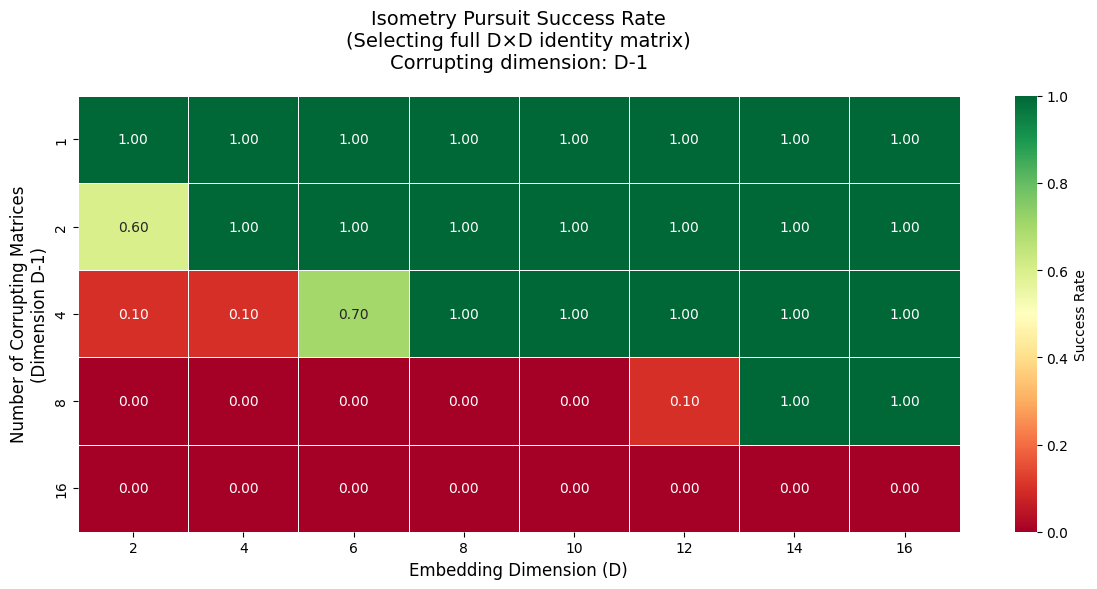

In [89]:
# Create heatmap
heatmap_data = success_rates.pivot(index='num_corrupting', columns='D', values='success_rate')

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, 
            cbar_kws={'label': 'Success Rate'}, linewidths=0.5, 
            xticklabels=True, yticklabels=True)
plt.title('Isometry Pursuit Success Rate\n(Selecting full D×D identity matrix)\nCorrupting dimension: D-1', 
          fontsize=14, pad=20)
plt.xlabel('Embedding Dimension (D)', fontsize=12)
plt.ylabel('Number of Corrupting Matrices\n(Dimension D-1)', fontsize=12)
plt.tight_layout()
plt.show()


In [90]:
# Summary statistics
print("Summary Statistics:")
print(f"\nOverall success rate: {results_df['success'].mean():.2%}")
print(f"\nSuccess rate by embedding dimension (D):")
print(results_df.groupby('D')['success'].mean())
print(f"\nSuccess rate by number of corrupting matrices:")
print(results_df.groupby('num_corrupting')['success'].mean())
print(f"\nConfigurations with 100% success:")
perfect = success_rates[success_rates['success_rate'] == 1.0]
print(perfect[['D', 'num_corrupting', 'success_rate']].to_string(index=False))
print(f"\nConfigurations with <100% success:")
imperfect = success_rates[success_rates['success_rate'] < 1.0]
if len(imperfect) > 0:
    print(imperfect[['D', 'num_corrupting', 'success_rate']].to_string(index=False))
else:
    print("  None - all configurations achieved 100% success!")


Summary Statistics:

Overall success rate: 59.00%

Success rate by embedding dimension (D):
D
2     0.34
4     0.42
6     0.54
8     0.60
10    0.60
12    0.62
14    0.80
16    0.80
Name: success, dtype: float64

Success rate by number of corrupting matrices:
num_corrupting
1     1.0000
2     0.9500
4     0.7375
8     0.2625
16    0.0000
Name: success, dtype: float64

Configurations with 100% success:
 D  num_corrupting  success_rate
 2               1           1.0
 4               1           1.0
 4               2           1.0
 6               1           1.0
 6               2           1.0
 8               1           1.0
 8               2           1.0
 8               4           1.0
10               1           1.0
10               2           1.0
10               4           1.0
12               1           1.0
12               2           1.0
12               4           1.0
14               1           1.0
14               2           1.0
14               4           1.0
1

# Random Vectors Corruption Experiment

This experiment tests isometry pursuit with a different corruption pattern:
- **Target**: 1 D×D identity matrix
- **Corruption**: 1 (D-1)×(D-1) identity matrix embedded in D dimensions
- **Additional corruption**: Variable number of random D-dimensional unit vectors (normalized Gaussian)

**X-axis**: Embedding dimension (D)  
**Y-axis**: Number of random vectors

For each configuration, we test whether isometry pursuit correctly selects the full D×D identity matrix.


In [91]:
# Random Vectors Experiment
# Define parameter grid
D_values = [2, 4, 6, 8, 10, 12, 14, 16]  # Embedding dimensions (x-axis)
num_random_vectors_values = [0, 1, 2, 4, 8, 16, 32]  # Number of random vectors (y-axis)
n_replicates = 10  # Replicates per configuration

print("Experimental Design:")
print(f"Embedding dimensions (D): {D_values}")
print(f"Number of random vectors: {num_random_vectors_values}")
print(f"Corruption: 1 (D-1)×(D-1) identity + num_random_vectors random unit vectors")
print(f"Replicates per configuration: {n_replicates}")

total_configs = len(D_values) * len(num_random_vectors_values)
total_runs = total_configs * n_replicates
print(f"\nTotal configurations: {total_configs}")
print(f"Total runs: {total_runs}")


Experimental Design:
Embedding dimensions (D): [2, 4, 6, 8, 10, 12, 14, 16]
Number of random vectors: [0, 1, 2, 4, 8, 16, 32]
Corruption: 1 (D-1)×(D-1) identity + num_random_vectors random unit vectors
Replicates per configuration: 10

Total configurations: 56
Total runs: 560


In [92]:
# Run random vectors experiment
results_random = []

for D in tqdm(D_values, desc="Embedding dimension"):
    corrupting_dim = D - 1  # (D-1)×(D-1) identity
    
    for num_random_vectors in tqdm(num_random_vectors_values, desc=f"D={D}, num_random", leave=False):
        # Build matrix_specs: 1 full D×D identity + 1 (D-1)×(D-1) identity
        matrix_specs = [(D, 1), (corrupting_dim, 1)]
        
        successes = 0
        for rep in range(n_replicates):
            # Generate identity matrices using generate_orthogonal_data
            data_tensor, _ = generate_orthogonal_data(
                output_dir=f"data/random_vectors_D{D}_nv{num_random_vectors}_rep{rep}",
                matrix_specs=matrix_specs,
                n_replicates=1,
                embedding_dim=D,
                noise_level=0.0,
                seed=1234 + rep  # Different seed for each replicate
            )
            
            # Extract the identity matrices: shape (D, D + (D-1))
            X_identities = data_tensor[0, :, :]  # Shape: (D, D + (D-1))
            
            # Generate random unit vectors (normalized Gaussian)
            np.random.seed(1234 + rep + 10000)  # Different seed for random vectors
            if num_random_vectors > 0:
                random_vectors = np.random.randn(D, num_random_vectors)
                # Normalize to unit vectors
                random_vectors = random_vectors / np.linalg.norm(random_vectors, axis=0, keepdims=True)
            else:
                random_vectors = np.zeros((D, 0))
            
            # Concatenate: identities first, then random vectors
            X = np.hstack([X_identities, random_vectors])  # Shape: (D, D + (D-1) + num_random_vectors)
            
            # Run isometry pursuit
            result = isometry_pursuit(X, power=1.0)
            selected_indices = result["basis_pursuit_indices"]
            
            # Check if correct: selected indices should be [0, 1, ..., D-1]
            expected_indices = set(range(D))
            selected_set = set(selected_indices)
            is_correct = (selected_set == expected_indices)
            
            if is_correct:
                successes += 1
            
            # Store result
            results_random.append({
                'D': D,
                'num_random_vectors': num_random_vectors,
                'corrupting_dim': corrupting_dim,
                'replicate': rep,
                'success': is_correct,
                'num_selected': len(selected_indices)
            })
        
        success_rate = successes / n_replicates
        print(f"D={D}, num_random_vectors={num_random_vectors}: {successes}/{n_replicates} successes ({success_rate:.1%})")

# Convert to DataFrame
results_random_df = pd.DataFrame(results_random)
print(f"\nExperiment complete! Total runs: {len(results_random_df)}")


Embedding dimension:   0%|                                                                          | 0/8 [00:00<?, ?it/s]/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/pytho

Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 1 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
Total matrices: 2
Total samples: 3 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 3)
Data tensor saved to data/random_vectors_D2_nv0_rep0/orthogonal_data_tensor.npy
Metadata saved to data/random_vectors_D2_nv0_rep0/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 1 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
Total matrices: 2
Total samples: 3 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 3)
Data tensor saved to data/random_vectors_D2_nv0_rep1/orthogonal_data_tensor.npy
Metadata saved to data/random_vectors_D2_nv0_rep1/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating 1 2

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting

Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 1 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
Total matrices: 2
Total samples: 3 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 3)
Data tensor saved to data/random_vectors_D2_nv0_rep6/orthogonal_data_tensor.npy
Metadata saved to data/random_vectors_D2_nv0_rep6/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating 1 2-dimensional orthogonal matrices...
  Matrix 1: shape (2, 2)
Generating 1 1-dimensional orthogonal matrices...
  Matrix 1: shape (2, 1)
Total matrices: 2
Total samples: 3 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 2, 3)
Data tensor saved to data/random_vectors_D2_nv0_rep7/orthogonal_data_tensor.npy
Metadata saved to data/random_vectors_D2_nv0_rep7/orthogonal_data_metadata.json
Generating orthogonal matrices...
Generating 1 2

/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting

...

Generating orthogonal matrices...
Generating 1 16-dimensional orthogonal matrices...
  Matrix 1: shape (16, 16)
Generating 1 15-dimensional orthogonal matrices...
  Matrix 1: shape (16, 15)
Total matrices: 2
Total samples: 31 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 16, 31)
Data tensor saved to data/random_vectors_D16_nv32_rep8/orthogonal_data_tensor.npy
Metadata saved to data/random_vectors_D16_nv32_rep8/orthogonal_data_metadata.json


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: divide by zero encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: overflow encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded
/Users/samsonkoelle/isometry-pursuit/isometry_pursuit/exec/generate_orthogonal_data.py:74: RuntimeWarning: invalid value encountered in matmul
  Q_rotated = rotation_matrix @ Q_embedded


Generating orthogonal matrices...
Generating 1 16-dimensional orthogonal matrices...
  Matrix 1: shape (16, 16)
Generating 1 15-dimensional orthogonal matrices...
  Matrix 1: shape (16, 15)
Total matrices: 2
Total samples: 31 (dimension samples per matrix)
Generating 1 replicates...
Generated data tensor shape: (1, 16, 31)
Data tensor saved to data/random_vectors_D16_nv32_rep9/orthogonal_data_tensor.npy
Metadata saved to data/random_vectors_D16_nv32_rep9/orthogonal_data_metadata.json


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
Embedding dimension: 100%|██████████████████████████████████████████████████████████████████| 8/8 [10:13<00:00, 76.67s/it]

D=16, num_random_vectors=32: 10/10 successes (100.0%)

Experiment complete! Total runs: 560


In [93]:
# Compute success rates by configuration
success_rates_random = results_random_df.groupby(['D', 'num_random_vectors']).agg({
    'success': ['sum', 'count', 'mean']
}).reset_index()
success_rates_random.columns = ['D', 'num_random_vectors', 'successes', 'total', 'success_rate']

print("Success Rates by Configuration:")
print(success_rates_random.to_string(index=False))


Success Rates by Configuration:
 D  num_random_vectors  successes  total  success_rate
 2                   0         10     10           1.0
 2                   1          4     10           0.4
 2                   2          3     10           0.3
 2                   4          1     10           0.1
 2                   8          0     10           0.0
 2                  16          0     10           0.0
 2                  32          0     10           0.0
 4                   0         10     10           1.0
 4                   1         10     10           1.0
 4                   2         10     10           1.0
 4                   4         10     10           1.0
 4                   8          5     10           0.5
 4                  16          0     10           0.0
 4                  32          0     10           0.0
 6                   0         10     10           1.0
 6                   1         10     10           1.0
 6                   2         10

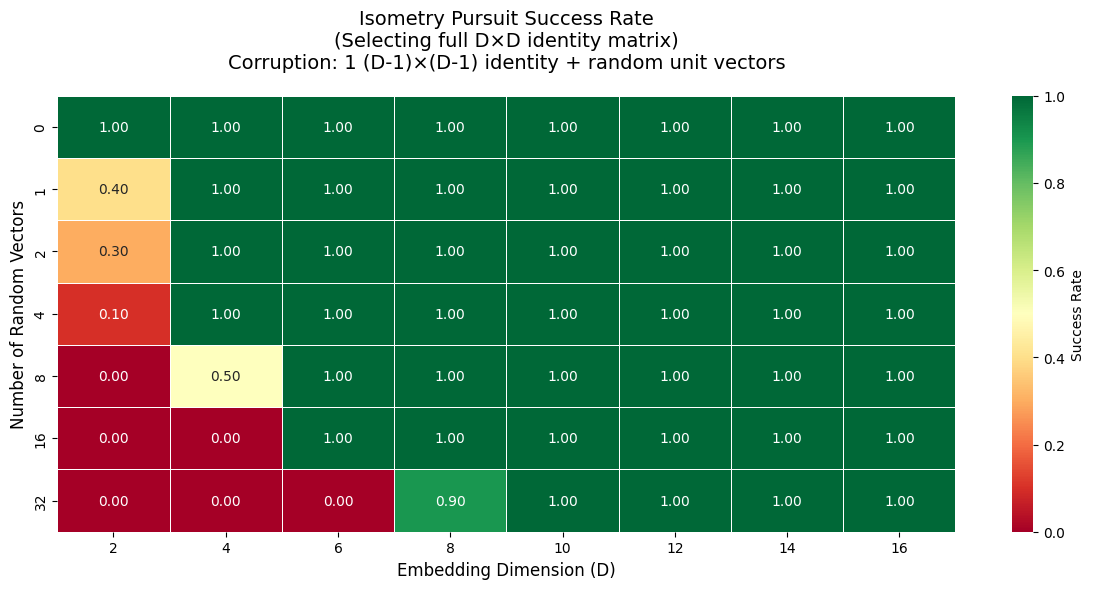

In [94]:
# Create heatmap
heatmap_data_random = success_rates_random.pivot(index='num_random_vectors', columns='D', values='success_rate')

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data_random, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, 
            cbar_kws={'label': 'Success Rate'}, linewidths=0.5, 
            xticklabels=True, yticklabels=True)
plt.title('Isometry Pursuit Success Rate\n(Selecting full D×D identity matrix)\nCorruption: 1 (D-1)×(D-1) identity + random unit vectors', 
          fontsize=14, pad=20)
plt.xlabel('Embedding Dimension (D)', fontsize=12)
plt.ylabel('Number of Random Vectors', fontsize=12)
plt.tight_layout()
plt.show()


In [95]:
# Summary statistics
print("Summary Statistics:")
print(f"\nOverall success rate: {results_random_df['success'].mean():.2%}")
print(f"\nSuccess rate by embedding dimension (D):")
print(results_random_df.groupby('D')['success'].mean())
print(f"\nSuccess rate by number of random vectors:")
print(results_random_df.groupby('num_random_vectors')['success'].mean())
print(f"\nConfigurations with 100% success:")
perfect_random = success_rates_random[success_rates_random['success_rate'] == 1.0]
print(perfect_random[['D', 'num_random_vectors', 'success_rate']].to_string(index=False))
print(f"\nConfigurations with <100% success:")
imperfect_random = success_rates_random[success_rates_random['success_rate'] < 1.0]
if len(imperfect_random) > 0:
    print(imperfect_random[['D', 'num_random_vectors', 'success_rate']].to_string(index=False))
else:
    print("  None - all configurations achieved 100% success!")


Summary Statistics:

Overall success rate: 84.29%

Success rate by embedding dimension (D):
D
2     0.257143
4     0.642857
6     0.857143
8     0.985714
10    1.000000
12    1.000000
14    1.000000
16    1.000000
Name: success, dtype: float64

Success rate by number of random vectors:
num_random_vectors
0     1.0000
1     0.9250
2     0.9125
4     0.8875
8     0.8125
16    0.7500
32    0.6125
Name: success, dtype: float64

Configurations with 100% success:
 D  num_random_vectors  success_rate
 2                   0           1.0
 4                   0           1.0
 4                   1           1.0
 4                   2           1.0
 4                   4           1.0
 6                   0           1.0
 6                   1           1.0
 6                   2           1.0
 6                   4           1.0
 6                   8           1.0
 6                  16           1.0
 8                   0           1.0
 8                   1           1.0
 8                  